# Joining two tables

Join a key-value table to a small lookup table and retain one row per matching key.

Both inputs must be sorted on the join field under the same collation rules. A join can multiply rows when a key is repeated on either side. Here each key appears once on each side.

In [1]:
from pathlib import Path
import shutil, subprocess, tempfile
import matplotlib.pyplot as plt
import numpy as np

here = Path.cwd()

## Native source

`example.sh`

```sh
#!/bin/sh
set -eu
export LC_ALL=C
printf '%s\n' 'c 7' 'a 3' 'b 5' | sort > readings
printf '%s\n' 'b 2' 'c 4' 'a 1' | sort > scales
join readings scales | awk '{print $2 * $3}'
```

## Run the shell script

The Python driver gives each installed shell its own empty working directory. Each run must agree with the independently specified fixture.

In [2]:
expected = [3, 10, 28]
shells = [name for name in ("sh", "bash", "zsh") if shutil.which(name)]
runs = {}
for shell in shells:
    with tempfile.TemporaryDirectory() as directory:
        result = subprocess.run(
            [shell, str(here / "example.sh")],
            cwd=directory,
            check=True,
            capture_output=True,
            text=True,
        )
    numbers = [int(v) for v in result.stdout.split()]
    runs[shell] = numbers
    print(shell, numbers)
    assert numbers == expected
observed = runs[shells[0]]

sh [3, 10, 28]
bash [3, 10, 28]
zsh [3, 10, 28]


## Inspect the outcome

The output order follows the sorted join key. A missing key drops out of this inner join.

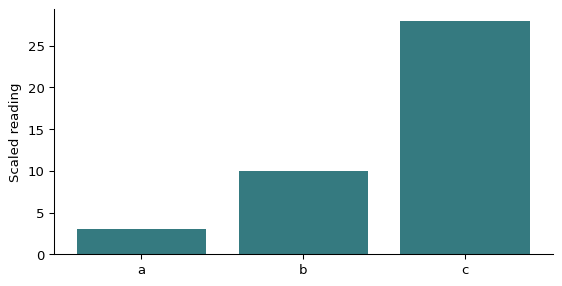

In [3]:
fig, ax = plt.subplots(figsize=(5.8, 2.9), constrained_layout=True)
ax.bar(["a", "b", "c"], observed, color="#357a80")
ax.set(ylabel="Scaled reading")
plt.show()

## Interpreting the result

The output order follows the sorted join key. A missing key drops out of this inner join.

## Exercise

Remove one lookup row and compare the output with a left join.

## References

[The Open Group, POSIX shell command language](https://pubs.opengroup.org/onlinepubs/9799919799/utilities/V3_chap02.html)

[GNU Bash reference manual](https://www.gnu.org/software/bash/manual/bash.html)

[Apple Terminal User Guide](https://support.apple.com/guide/terminal/welcome-trml2df0220c/mac)